In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import seaborn as sns

In [3]:
# Chemin des donnees
DATA_PATH = Path("data/raw/regularite-mensuelle-tgv-aqst.csv")

# Charger les donnees
df_raw = pd.read_csv(DATA_PATH, sep=";")

# Afficher les 5 premieres lignes
print(df_raw.head())

      Date   Service      Gare de départ      Gare d'arrivée  \
0  2018-01  National    BORDEAUX ST JEAN  PARIS MONTPARNASSE   
1  2018-01  National             LE MANS  PARIS MONTPARNASSE   
2  2018-01  National  PARIS MONTPARNASSE   LA ROCHELLE VILLE   
3  2018-01  National  PARIS MONTPARNASSE              NANTES   
4  2018-01  National            POITIERS  PARIS MONTPARNASSE   

   Durée moyenne du trajet  Nombre de circulations prévues  \
0                      141                             870   
1                       56                             406   
2                      166                             226   
3                      124                             508   
4                       94                             472   

   Nombre de trains annulés  Commentaire annulations  \
0                         5                      NaN   
1                         1                      NaN   
2                         0                      NaN   
3                 

In [4]:
# Informations generales
print(df_raw.info())

<class 'pandas.DataFrame'>
RangeIndex: 12907 entries, 0 to 12906
Data columns (total 26 columns):
 #   Column                                                                                       Non-Null Count  Dtype  
---  ------                                                                                       --------------  -----  
 0   Date                                                                                         12907 non-null  str    
 1   Service                                                                                      12907 non-null  str    
 2   Gare de départ                                                                               12907 non-null  str    
 3   Gare d'arrivée                                                                               12907 non-null  str    
 4   Durée moyenne du trajet                                                                      12907 non-null  int64  
 5   Nombre de circulations prévues             

On a deux colonnes vides, à savoir : **"Commentaire retards au départ"** et **"Nombre de trains en retard au départ"**. 


In [5]:
# Nous allons afficher le nombre de valeurs manquantes par colonne
nb_NaN_par_colonne = df_raw.isna().sum()
print(f"Nombre de valeurs manquantes par colonne :\n{nb_NaN_par_colonne}")

Nombre de valeurs manquantes par colonne :
Date                                                                                               0
Service                                                                                            0
Gare de départ                                                                                     0
Gare d'arrivée                                                                                     0
Durée moyenne du trajet                                                                            0
Nombre de circulations prévues                                                                     0
Nombre de trains annulés                                                                           0
Commentaire annulations                                                                        12907
Nombre de trains en retard au départ                                                               0
Retard moyen des trains en retard au départ     

In [6]:
# Pourcentage de donnees manquantes
nb_lignes = len(df_raw)
pct_NaN_par_colonne = ((nb_NaN_par_colonne / nb_lignes) * 100).round(2)
print(f"Pourcentage de données manquantes par colonne :\n{pct_NaN_par_colonne}")

Pourcentage de données manquantes par colonne :
Date                                                                                             0.00
Service                                                                                          0.00
Gare de départ                                                                                   0.00
Gare d'arrivée                                                                                   0.00
Durée moyenne du trajet                                                                          0.00
Nombre de circulations prévues                                                                   0.00
Nombre de trains annulés                                                                         0.00
Commentaire annulations                                                                        100.00
Nombre de trains en retard au départ                                                             0.00
Retard moyen des trains en retard 

- Seulement 5% des valeurs de la colonne **"Commentaire retards à l'arrivée"** sont exploitables
-  Nous avons déjà vu que les colonnes **"Commentaire annulations"** et  **"Commentaire retards au départ"** étaient vides, d'où 100% de valeurs manquantes
 
Nous pouvons donc déjà supprimer ces deux colonnes vides

In [7]:
# Le nombre de lignes dupliquees
print(f"Nombre de lignes dupliquées : {df_raw.duplicated().sum()}")

# Si on avait des lignes dupliquees, on aurait fait 'df.drop_duplicates()' pour supprimer les
# doublons

Nombre de lignes dupliquées : 0


Aucune ligne n'est dupliquée

In [8]:
# Analyse statistique descriptive
print(df_raw.describe())

       Durée moyenne du trajet  Nombre de circulations prévues  \
count             12907.000000                    12907.000000   
mean                170.693112                      273.443635   
std                  87.726724                      184.117868   
min                   0.000000                        0.000000   
25%                  99.000000                      151.000000   
50%                 163.000000                      231.000000   
75%                 223.000000                      365.000000   
max                 786.000000                     1104.000000   

       Nombre de trains annulés  Commentaire annulations  \
count              12907.000000                      0.0   
mean                   8.273650                      NaN   
std                   21.805356                      NaN   
min                    0.000000                      NaN   
25%                    0.000000                      NaN   
50%                    2.000000              

- **Durée moyenne du trajet**<br>
C'est assez suspect 0 comme valeur minimale et 786, soit environ 13h de trajet, comme valeur maximale. Pour 0, aucun trajet n'a été effectué pendant le mois pour cette liaison ?

- **Nombre de circulations prévues**<br>
0 encore une fois suspect comme valeur min, ça veut dire pour pour cette liaison il ne prévoyait 
aucun trajet ?
75% du temps une liaison, on prévoit 365 trains, il serait interressant de voir quel est la 
liaison pour laquelle on prévoit 1104, est-ce une liaison importante

- **Nombre de trains annulés**<br>
Dans 75% du temps on annule 7 trains sur une liaison, il serait bien de voir quelle est la liaison
pour laquelle on a annulé 297 trains, est-ce une valeur abérante ?

- **Nombre de trains en retard au départ**<br>
0 trains en retard au départ ? Quelle est cette liaison ? Est-ce une liaison importante ?
598 trains en retard au départ ? Pourquoi ces retards au départ ?

- **Retard moyen des trains en retard au départ**<br>
Un train peut-il faire 316 minutes, soit environ 5h de retard au départ sans être annulé sachant 
que dans 75% du temps le retard au départ est de 16 minutes environ ?
Est-ce que le nom

- **<span style="color:red;">Retard moyen de tous les trains au départ</span>**<br>
J'observe une ***valeur min négative*** <br>
Quelle est cette liaison pour laquelle on a en moyenne 115 minutes de retard au départ ? <br>

- **Nombre de trains en retard à l'arrivée**
Quelle est la liaison qui a comptabilité 376 trains en retard à son arrivée pendant un mois ?
Est-ce normal ?

- **<span style="color:red;">Retard moyen des trains en retard à l'arrivée</span>**<br>
Je vois également une ***valeur minimale négative*** <br>
A quelle date et sur quelle ligne avons-nous eu autant de retard à l'arrivée (299.60 minutes, soit
environ 5h) ? <br>

- **<span style="color:red;">Retard moyen trains en retard > 15 (si liaison concurrencée par vol)</span>**<br>
Je vois également une ***valeur minimale négative*** <br>
Nous avons la même valeur max 299.60 que dans le cas des **Retard moyen des trains en retard à l'arrivée**

- **<span style="color:red;">Retard moyen de tous les trains à l'arrivée</span>** <br>
Je vois ***une valeur négative*** <br>
Quelle est la laison qui a eu 92 min de retard lorsque 75% du temps le retard était de 8 minutes 
environ ? A quelle période ? Quelles causes ? Est-ce exceptionnel ?

- **<span style="color:red;">Nombre trains en retard > 15min</span>** <br>
Je vois ***une valeur négative*** <br>

- **<span style="color:red;">Nombre trains en retard > 30min</span>** <br>
Je vois ***une valeur négative*** <br>




**Incohérences :**
- Date incorrecte
- Durée moyenne du trajet $< 0$ 
- Nombre de circulations prévues $< 0$
- Nombre de trains annulés $< 0$
- Nombre de trains en retard au départ $< 0$
- Retard moyen des trains en retard au départ $< 0$ 
- Retard moyen de tous les trains au départ $< 0$
- Retard moyen des trains en retard à l'arrivée $< 0$
- Retard moyen de tous les trains à l'arrivée $< 0$
- Nombre trains en retard > 15min $< 0$
- Retard moyen trains en retard > 15 (si liaison concurrencée par vol) $< 0$
- Nombre trains en retard > 30min $< 0$ 
- Nombre trains en retard > 60min $< 0$
- Nombre de trains annulés $>$ Nombre de circulations prévues
- Nombre de trains en retard au départ $>$ Nombre de circulations prévues
- Nombre trains en retard $>$ Nombre de circulations prévues
- (Nombre trains en retard > 15min $<$ Nombre trains en retard > 30min) OU (Nombre trains en retard > 30min $<$ Nombre trains en retard > 60min)
- Prct retard pour causes externes $\notin [0, 100]$ 
- Somme des pourcentages différente de 100

In [9]:
def construire_dataFrameDIncoherences(df: pd.DataFrame) -> pd.DataFrame:
    """
    Construit le dataFrame des regles d'incoherences SNCF.
    Leve une exception si la colonne 'Date_parsed' est absente
    """
    # ON FERA LE CONTROLE DE LA PRESENCE DES COLONNES SI BESOIN POUR L'INSTANT JE
    # SUPPOSE QUE TOUTES LES COLONNES SONT PRESENTES

    # Colonnes du DataFrame attendues------------------------------------------------------
    date_parsed = df["Date_parsed"]
    duree_moyenne_du_trajet = df["Durée moyenne du trajet"]
    nombre_de_circulations_prevues = df["Nombre de circulations prévues"]
    nombre_de_trains_annules = df["Nombre de trains annulés"]
    nombre_de_trains_en_retard_au_depart = df["Nombre de trains en retard au départ"]
    retard_moyen_des_trains_en_retard_au_depart = df[
        "Retard moyen des trains en retard au départ"
    ]
    retard_moyen_de_tous_les_trains_au_depart = df[
        "Retard moyen de tous les trains au départ"
    ]
    nombre_de_trains_en_retard_a_l_arrivee = df[
        "Nombre de trains en retard à l'arrivée"
    ]
    retard_moyen_des_trains_en_retard_a_l_arrivee = df[
        "Retard moyen des trains en retard à l'arrivée"
    ]
    retard_moyen_de_tous_les_trains_a_l_arrivee = df[
        "Retard moyen de tous les trains à l'arrivée"
    ]
    nombre_trains_en_retard_sup_15min = df["Nombre trains en retard > 15min"]
    retard_moyen_trains_en_retard_sup_15_si_liaison_concurrencee_par_vol = df[
        "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)"
    ]
    nombre_trains_en_retard_sup_30min = df["Nombre trains en retard > 30min"]
    nombre_trains_en_retard_sup_60min = df["Nombre trains en retard > 60min"]
    prct_retard_pour_causes_externes = df["Prct retard pour causes externes"]
    prct_retard_pour_cause_infrastructure = df["Prct retard pour cause infrastructure"]
    prc_retard_por_cause_materiel_roulant = df[
        "Prct retard pour cause matériel roulant"
    ]
    prct_retard_pour_cause_gestion_trafic = df["Prct retard pour cause gestion trafic"]
    prct_retard_pour_cause_gestion_en_gare_et_reutilisation_de_materiel = df[
        "Prct retard pour cause gestion en gare et réutilisation de matériel"
    ]
    prct_retard_pour_cause_prise_en_compte_voyageurs = df[
        "Prct retard pour cause prise en compte voyageurs "
        "(affluence, gestions PSH, correspondances)"
    ]

    # Construction du dictionnaire d'incoherence-------------------------------------------
    dict_incoherences = {
        "Date incorrecte": date_parsed.isna(),
        "Durée moyenne du trajet négative": duree_moyenne_du_trajet.lt(0),
        "Nombre de circulations prévues négatif": nombre_de_circulations_prevues.lt(0),
        "Nombre de trains annulés négatif": nombre_de_trains_annules.lt(0),
        "Nombre de trains en retard au départ négatif": nombre_de_trains_en_retard_au_depart.lt(
            0
        ),
        "Retard moyen des trains en "
        "retard au départ négatif": retard_moyen_des_trains_en_retard_au_depart.lt(0),
        "Retard moyen de tous les trains "
        "au départ négatif": retard_moyen_de_tous_les_trains_au_depart.lt(0),
        "Nombre de trains en retard à l'arrivée négatif": nombre_de_trains_en_retard_a_l_arrivee.lt(
            0
        ),
        "Retard moyen trains en retard "
        "à l'arrivée négatif": retard_moyen_des_trains_en_retard_a_l_arrivee.lt(0),
        "Retard moyen tous les trains "
        "à l'arrivée negatif": retard_moyen_de_tous_les_trains_a_l_arrivee.lt(0),
        "Nombre trains en retard > 15min négatif": nombre_trains_en_retard_sup_15min.lt(
            0
        ),
        "Retard moyen trains en retard > 15 "
        "(si liaison concurrencée par vol) négatif": retard_moyen_trains_en_retard_sup_15_si_liaison_concurrencee_par_vol.lt(
            0
        ),
        "Nombre trains en retard > 30min négatif": nombre_trains_en_retard_sup_30min.lt(
            0
        ),
        "Nombre trains en retard > 60min négatif": nombre_trains_en_retard_sup_60min.lt(
            0
        ),
        "Nombre de trains annulés > Nombre de circulations prévues": nombre_de_trains_annules
        > nombre_de_circulations_prevues,
        "Nombre de trains en retard au départ "
        "> Nombre de circulations prévues": nombre_de_trains_en_retard_au_depart
        > nombre_de_circulations_prevues,
        "Nombre de trains en retard à l'arrivée "
        "> Nombre de circulations prévues": nombre_de_trains_en_retard_a_l_arrivee
        > nombre_de_circulations_prevues,
        "Nombre trains en retard > 15min SUP "
        "Nombre de circulations prévues": nombre_trains_en_retard_sup_15min
        > nombre_de_circulations_prevues,
        "Nombre trains en retard > 30min SUP "
        "Nombre de circulations prévues": nombre_trains_en_retard_sup_30min
        > nombre_de_circulations_prevues,
        "Nombre trains en retard > 60min SUP "
        "Nombre de circulations prévues": nombre_trains_en_retard_sup_60min
        > nombre_de_circulations_prevues,
        "Incohérence des effectifs de trains en retard (seuils 15, 30 et 60 min)": (
            nombre_trains_en_retard_sup_15min < nombre_trains_en_retard_sup_30min
        )
        | (nombre_trains_en_retard_sup_30min < nombre_trains_en_retard_sup_60min),
        "Prct retard pour causes externes incohérent": prct_retard_pour_causes_externes.lt(
            0
        )
        | prct_retard_pour_causes_externes.gt(100),
        "Prct retard pour cause infrastructure incohérent": prct_retard_pour_cause_infrastructure.lt(
            0
        )
        | prct_retard_pour_cause_infrastructure.gt(100),
        "Prct retard pour cause matériel roulant incoherent": prc_retard_por_cause_materiel_roulant.lt(
            0
        ),
        "Prct retard pour cause gestion trafic incohérent": prct_retard_pour_cause_gestion_trafic.lt(
            0
        )
        | prct_retard_pour_cause_gestion_trafic.gt(100),
        "Prct_retard_pour_cause_gestion_en_gare_et_reutilisation_de_materiel incohérent": prct_retard_pour_cause_gestion_en_gare_et_reutilisation_de_materiel.lt(
            0
        )
        | prct_retard_pour_cause_gestion_en_gare_et_reutilisation_de_materiel.gt(100),
        "Prct retard pour cause prise en compte voyageurs incohérent": prct_retard_pour_cause_prise_en_compte_voyageurs.lt(
            0
        )
        | prct_retard_pour_cause_prise_en_compte_voyageurs.gt(100),
        "somme des pourcentages différente de 100": (
            prct_retard_pour_causes_externes
            + prct_retard_pour_cause_infrastructure
            + prc_retard_por_cause_materiel_roulant
            + prct_retard_pour_cause_gestion_trafic
            + prct_retard_pour_cause_gestion_en_gare_et_reutilisation_de_materiel
            + prct_retard_pour_cause_prise_en_compte_voyageurs
        )
        .sub(100)
        .abs()
        .gt(0.1),  # 0.1 représente la tolérance
    }

    # Retourner le dataFrame d'incohérences-------------------------------------------------
    return pd.DataFrame(dict_incoherences)

In [10]:
df_processed = df_raw.copy()

# 'errors="coerce"' permet de transformer les dates incorrectes en NaT
df_processed["Date_parsed"] = pd.to_datetime(
    df_raw["Date"],
    format="%Y-%m",
    errors="coerce",
)

# On definit le dataFrame d'incoherence
df_incoherences = construire_dataFrameDIncoherences(df_processed)

rapport_incoherences = df_incoherences.sum()
print(f"Rapport d'incohérences :\n{rapport_incoherences[rapport_incoherences.gt(0)]}")

# Nombre de lignes suspectes
masque_global = df_incoherences.any(axis=1)
nb_lignes_suspectes = masque_global.sum()

# Pourcentage des lignes suspectes :
pct_lignes_suspectes = (nb_lignes_suspectes * 100 / len(df_raw)).round(2)

print(f"\nPrct de lignes suspectes : {pct_lignes_suspectes}%")

Rapport d'incohérences :
Retard moyen de tous les trains au départ négatif                               170
Retard moyen trains en retard à l'arrivée négatif                                 2
Retard moyen tous les trains à l'arrivée negatif                                122
Retard moyen trains en retard > 15 (si liaison concurrencée par vol) négatif      8
Nombre trains en retard > 30min négatif                                          43
Nombre de trains annulés > Nombre de circulations prévues                        63
Incohérence des effectifs de trains en retard (seuils 15, 30 et 60 min)         357
somme des pourcentages différente de 100                                        282
dtype: int64

Prct de lignes suspectes : 6.74%


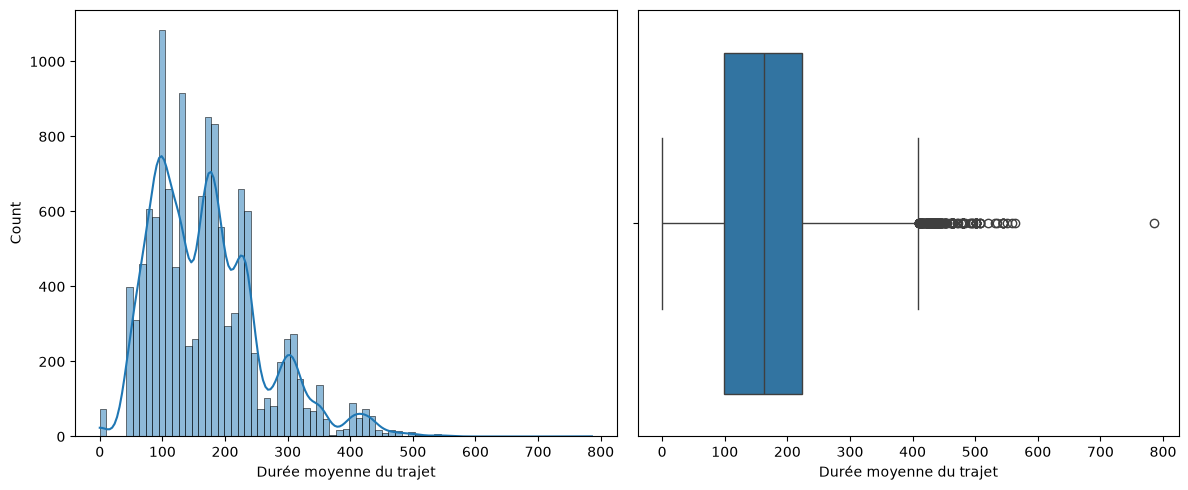

In [11]:
# Visualisation
colonne = "Durée moyenne du trajet"

plt.figure(figsize=(12, 5))

nb_lignes = 1
nb_colonnes = 2

# premier graphique : histogramme
ax1 = plt.subplot(nb_lignes, nb_colonnes, 1)
sns.histplot(
    data=df_raw,
    x=colonne,
    kde=True,  # Ajoute une courbe lisse estimée à l'histogramme
    ax=ax1,
)
# ax1.set_title("Distribution")

# 2e graphique : boxplot
ax2 = plt.subplot(nb_lignes, nb_colonnes, 2)
sns.boxplot(
    data=df_raw,
    x=colonne,
)
# ax2.set_title("boxplot")


plt.tight_layout()  # permet d'ajuster automatiquement les espaces entre les graphiques
plt.show()

On a 18 figures à afficher, et on veut afficher trois figure contenant 2 x 3 histplot() <br>
on va donc faire trois boucles for :

```python
for i in range(3) # pour les trois figures 
    for j in range(2) # Pour les 2 lignes 
        for k in range(3) # pour les 3 colonnes 
```
Pour la 1ère figure, **i = 0**, on a :
- pour j = 0 : idx = 0, 1, 2
- pour j = 1 : idx = 3, 4, 5 <br>
Lorsqu'on généralise, on a : $idx = j * 3 + k$

Pour la 2e figure, **i = 1**,  on a :
- pour j = 0 : idx = 6, 7, 8
- pour j = 1 : idx = 9, 10, 11 <br>
Lorsqu'on généralise, on a : $idx = 6 + j * 3 + k$

Pour la 2e figure, **i = 2**,  on a :
- pour j = 0 : idx = 12, 13, 14
- pour j = 1 : idx = 15, 16, 17 <br>
Lorsqu'on généralise, on a : $idx = (6 * 2) + j * 3 + k$

==> On peut donc tout généraliser par : <br>
$idx = (6 * i) + (j * 3) + k$




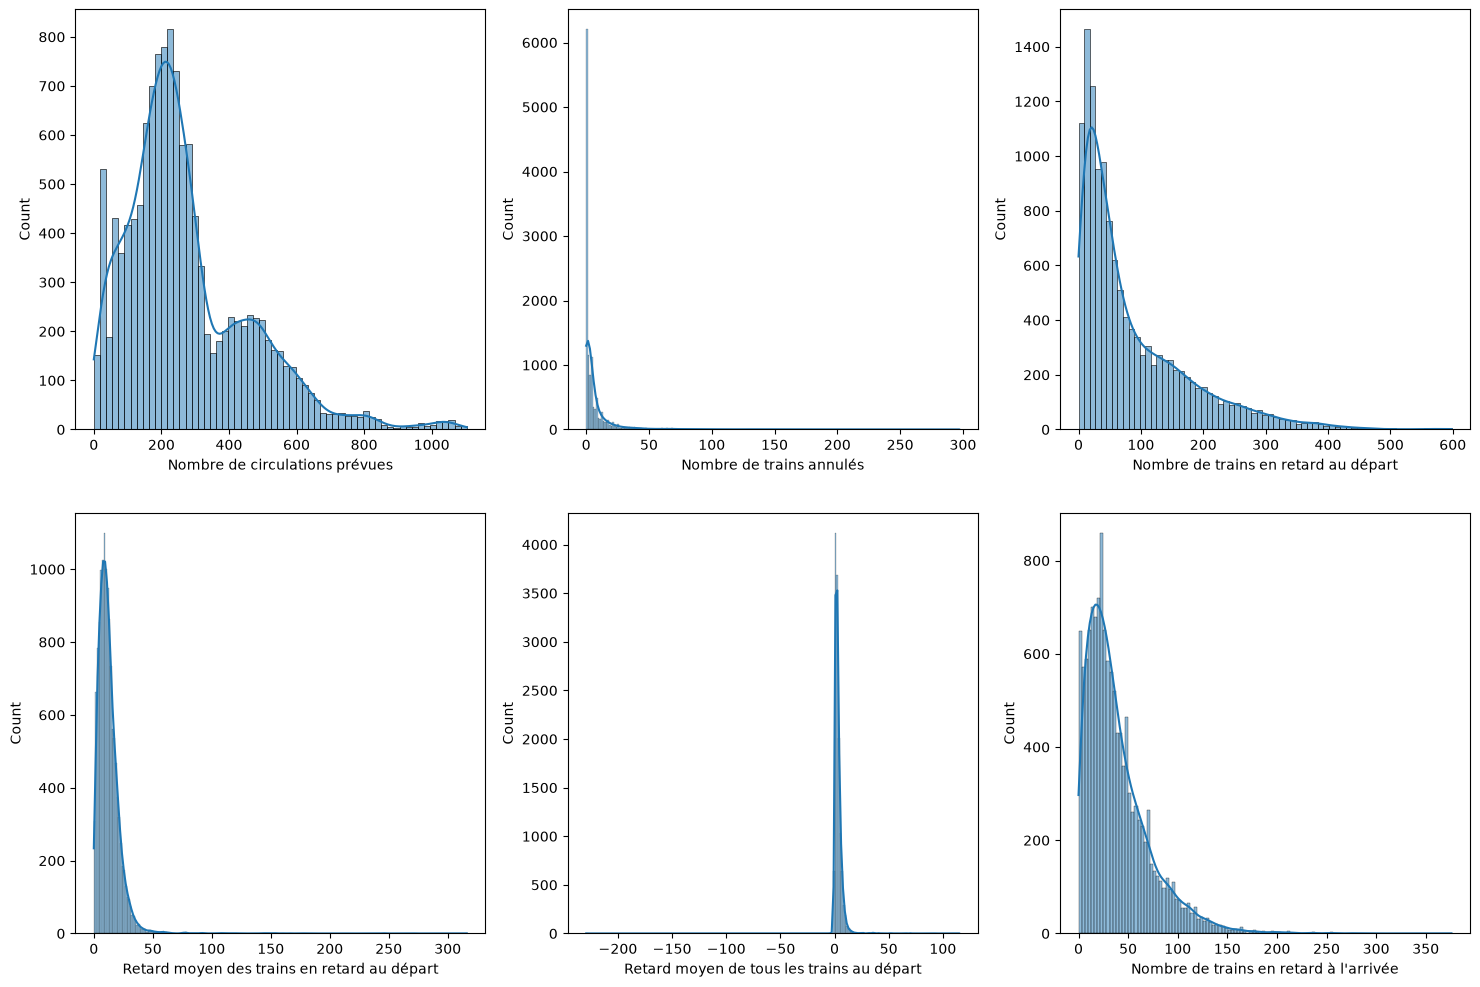

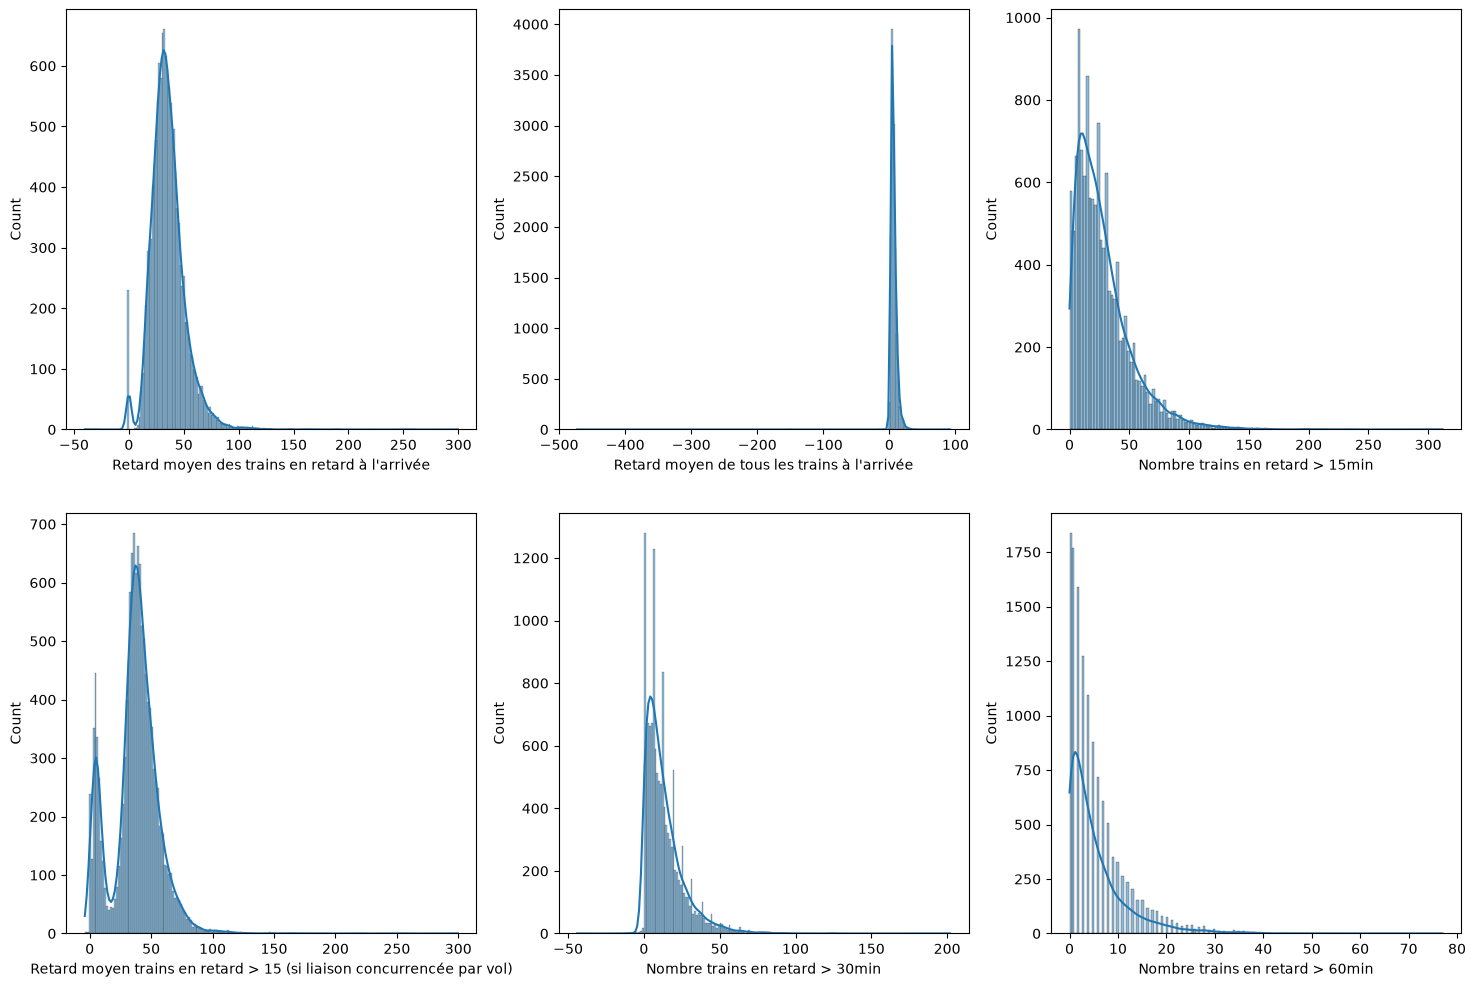

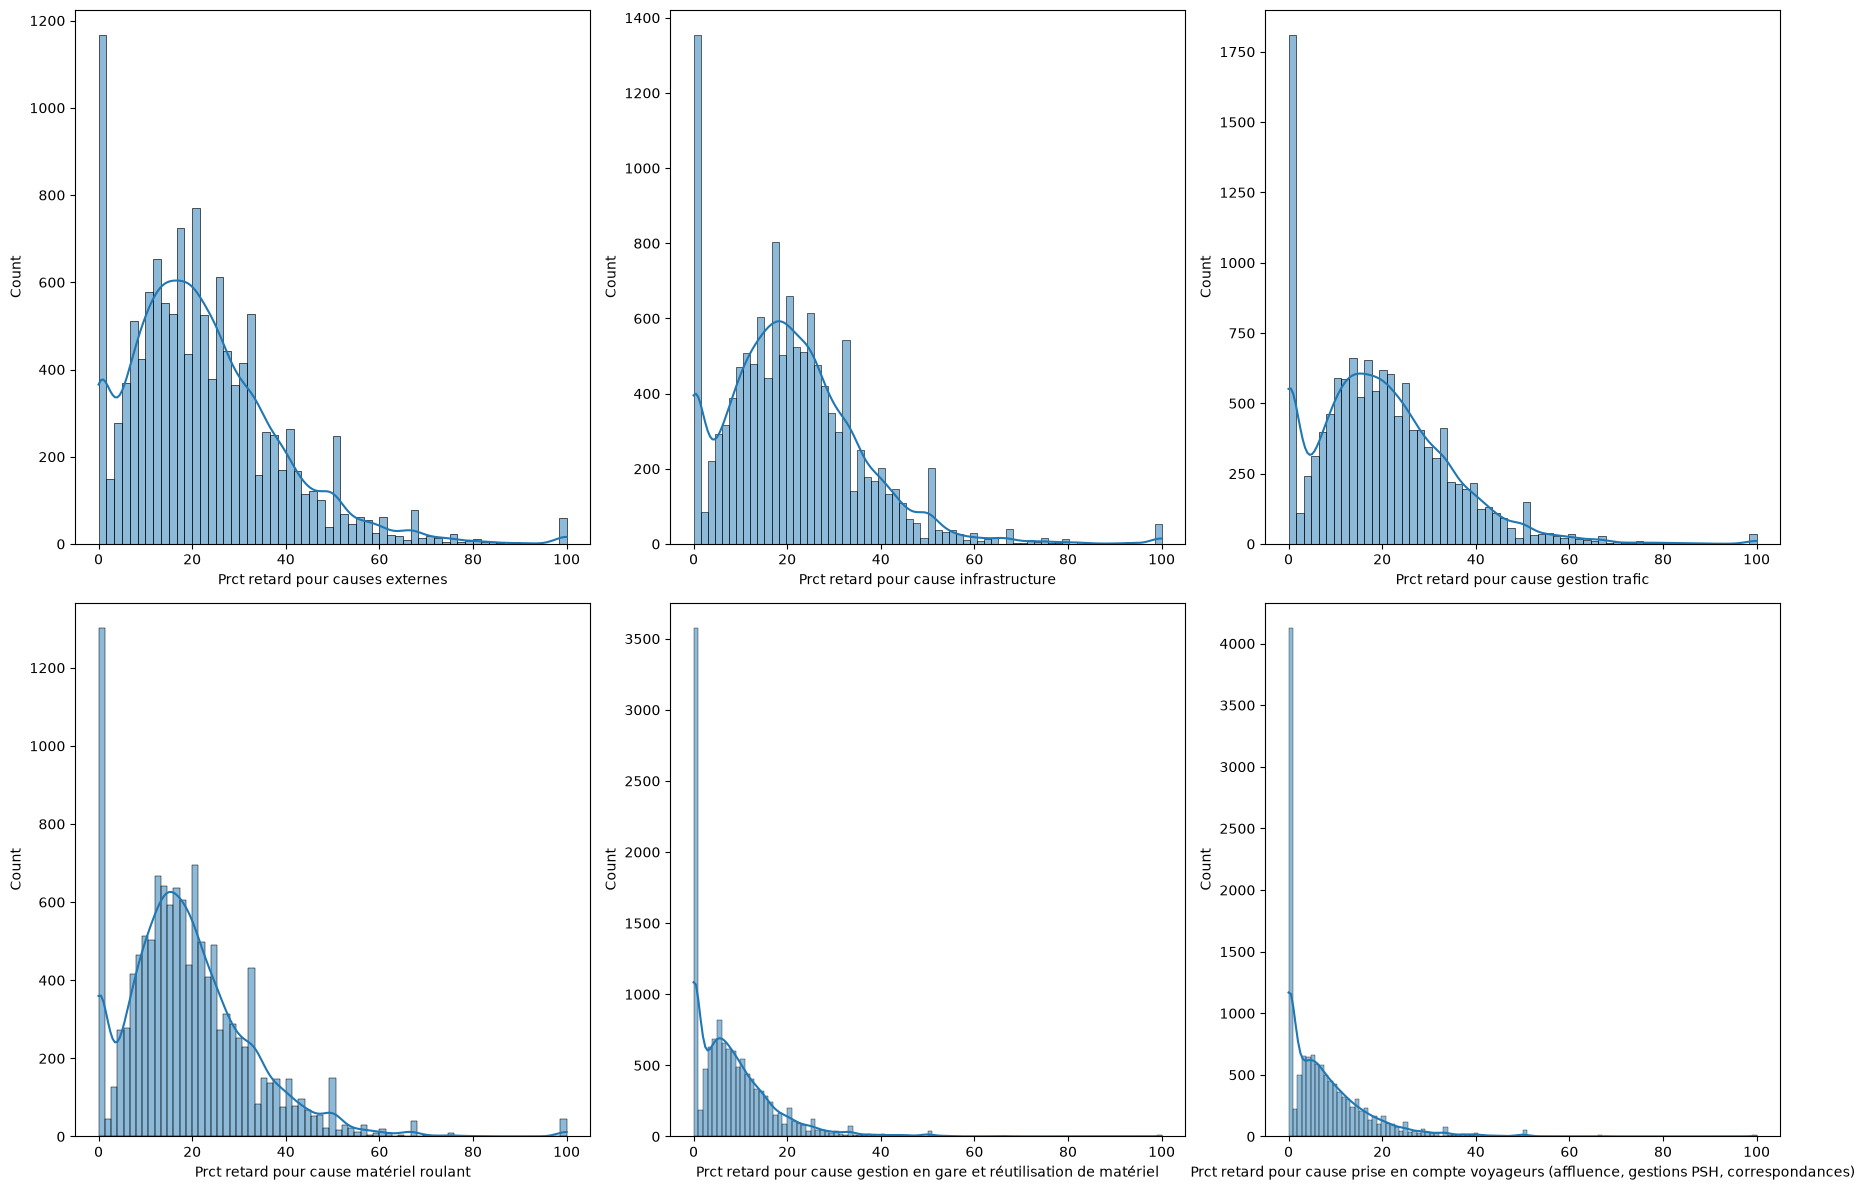

In [ ]:
# Selection des colonnes ayant des nombres, en retirant la colonne "Durée moyenne du trajet"
# 'dropna(axis=1, how="all")' c'est pour supprimer les colonnes qui ne contiennent que des NaN
colonnes = (
    df_raw.select_dtypes(include="number")
    .dropna(axis=1, how="all")
    .columns.drop("Durée moyenne du trajet")
)

# Création figures et des subplots
nb_figures = 3
nb_lignes = 2
nb_colonnes = 3

for i in range(nb_figures):
    fig, axes = plt.subplots(nb_lignes, nb_colonnes, figsize=(18, 12))
    for j in range(nb_lignes):
        for k in range(nb_colonnes):
            # Indice pour l'affichage des noms des colonnes
            idx = (i * (nb_lignes * nb_colonnes)) + (j * nb_figures) + k
            sns.histplot(
                data=df_raw,
                x=colonnes[idx],
                kde=True,  # Ajoute une courbe lisse estimée à l'histogramme
                ax=axes[j, k],
            )
            # axes[j, k].set_title("Distribution " + colonnes[idx].lower())
plt.tight_layout()
plt.show()

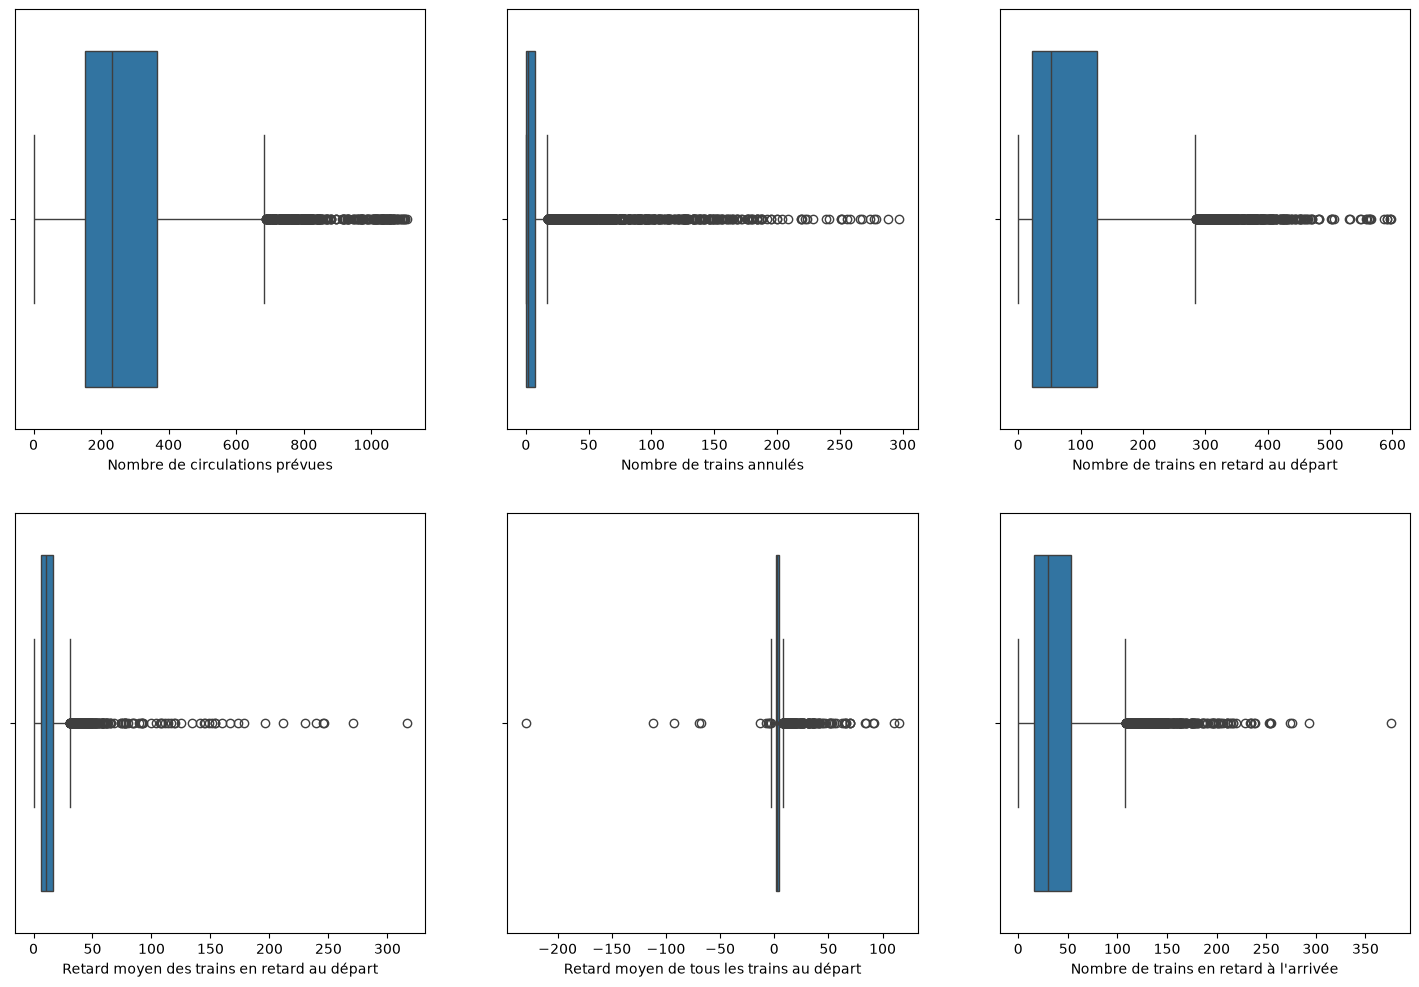

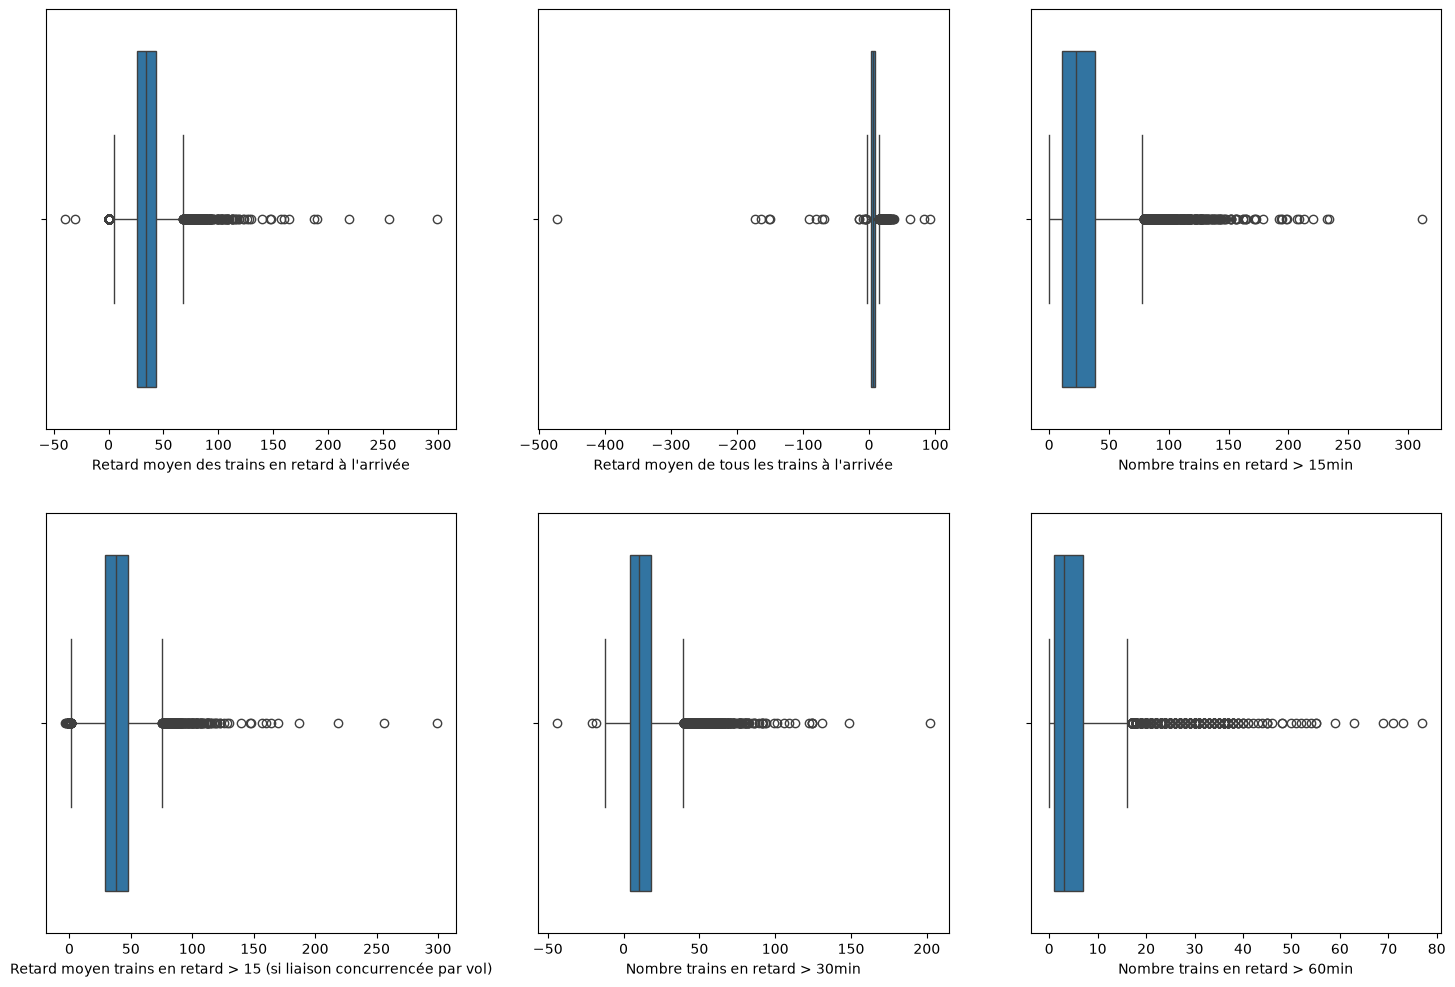

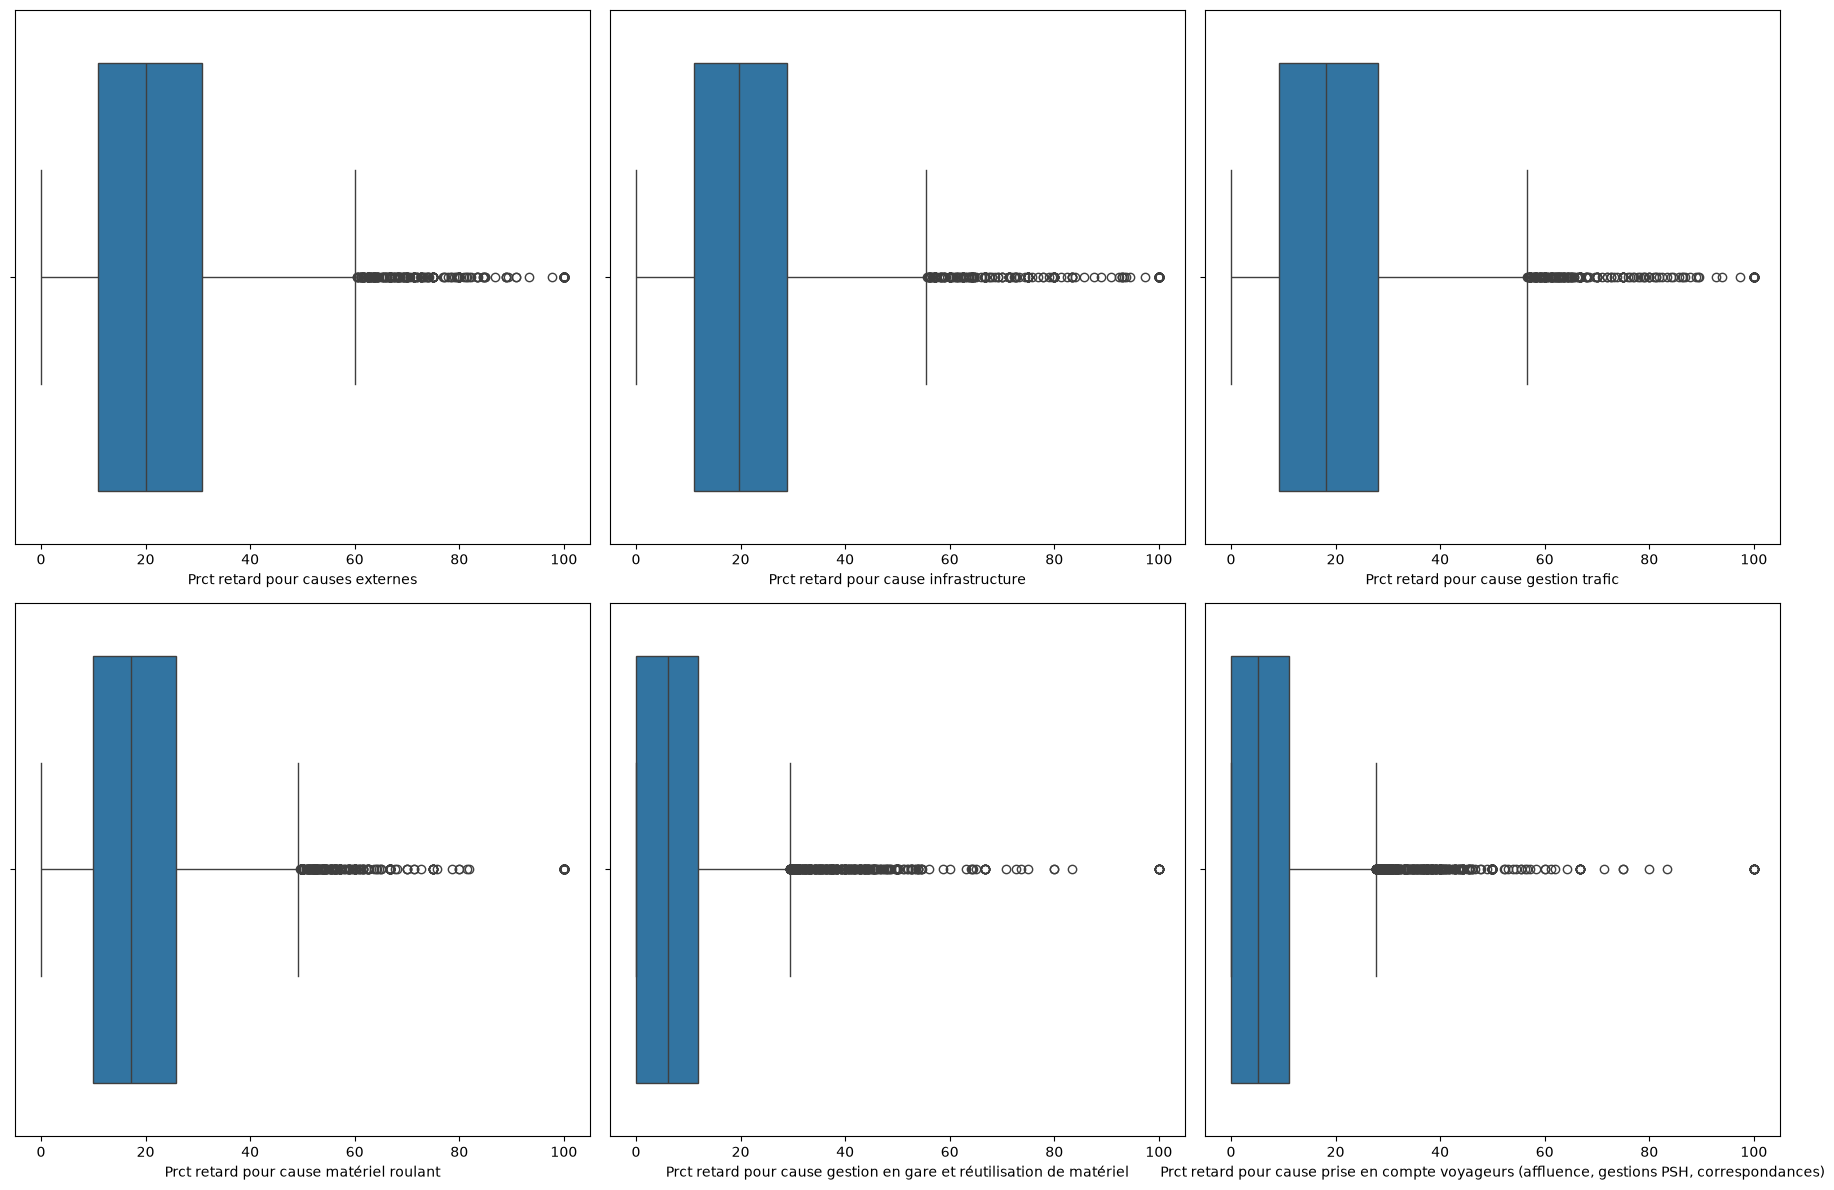

In [13]:
for i in range(nb_figures):
    fig, axes = plt.subplots(nb_lignes, nb_colonnes, figsize=(18, 12))
    for j in range(nb_lignes):
        for k in range(nb_colonnes):
            # Indice pour l'affichage des noms des colonnes
            idx = (i * (nb_lignes * nb_colonnes)) + (j * nb_figures) + k
            sns.boxplot(
                data=df_raw,
                x=colonnes[idx],
                ax=axes[j, k],
            )
            # axes[j, k].set_title("Distribution " + colonnes[idx].lower())
plt.tight_layout()
plt.show()

In [14]:
def get_masque_lignes_incoherentes(
    df: pd.DataFrame,
    colonnes: list[str],
) -> pd.Series:
    """Retourne un masque selon les clés du dictionnaire d'incohérences."""
    if not colonnes:
        return pd.Series(False, index=df.index)

    return df[colonnes].any(axis=1)

Je vais sélectionner les colonnes qui m'interressent, à savoir les colonnes sur les **pourcentages des causes de retards**

In [ ]:
# Pour ne pas se limiter dans les affichages
pd.set_option("display.max_columns", None)

# On va sélectionner les lignes avec les incohérences par rapport a ce qui m'interresse
colonnes = [
    "Prct retard pour causes externes incohérent",
    "Prct retard pour cause matériel roulant incoherent",
    "Prct retard pour cause gestion trafic incohérent",
    "Prct_retard_pour_cause_gestion_en_gare_et_reutilisation_de_materiel incohérent",
    "Prct retard pour cause prise en compte voyageurs incohérent",
    "somme des pourcentages différente de 100",
]

# Les colonnes du dataframe liées au retard
colonnes_causes = [
    colonne
    for colonne in df_processed.columns
    if colonne.startswith("Prct retard pour")
]

# masque des lignes présentant des incoherences sélectionnées dans 'colonnes'
masque_incoherences_selectionnees = get_masque_lignes_incoherentes(
    df_incoherences, colonnes
)

df_processed["somme prct retard"] = df_processed[colonnes_causes].sum(axis=1)
df_avec_incoherences_selectionnees = df_processed[masque_incoherences_selectionnees]

print(df_avec_incoherences_selectionnees.head(10))

        Date        Service        Gare de départ   Gare d'arrivée  \
318  2018-03       National  MARSEILLE ST CHARLES        TOURCOING   
389  2018-03  International  MARSEILLE ST CHARLES           MADRID   
421  2018-04       National  MARSEILLE ST CHARLES        TOURCOING   
495  2018-04  International  MARSEILLE ST CHARLES           MADRID   
508  2018-04       National                RENNES  PARIS VAUGIRARD   
536  2018-05       National      BELLEGARDE (AIN)       PARIS LYON   
546  2018-05  International            PARIS LYON           ITALIE   
547  2018-05  International              LAUSANNE       PARIS LYON   
548  2018-05  International            PARIS LYON           ZURICH   
571  2018-05  International             PARIS EST        FRANCFORT   

     Durée moyenne du trajet  Nombre de circulations prévues  \
318                      302                              31   
389                      464                              31   
421                      301         

C'est assez bizarre, nous avons des trains en retard à l'arrivée pour certaines liaisons, mais le pourcentage total des retards est de 0. C'est une **incohérence**.

On va donc afficher les liaisons pour lesquels on a la somme des pourcentages nulle, et un nombre de trains en retard à l'arrivée nulle, et les liaisons où la somme des pourcentages est nulle, mais avec un nombre de trains en retard à l'arrivée différent de 0

In [16]:
cols_retards = "Nombre de trains en retard à l'arrivée"
masque_sans_retard = df_processed[cols_retards] == 0
masque_somme_prct_nulle = df_processed["somme prct retard"] == 0
masque_somme_prct_sup_100 = df_processed["somme prct retard"].gt(
    100.1
)  # 100.1 car precision de 0.1
masque_somme_prct_sup_0_inf_100 = df_processed["somme prct retard"].gt(
    0
) & df_processed["somme prct retard"].lt(99.9)  # 99.9 car precision de 0.1

print(f"somme prct retard nulle : {(masque_somme_prct_nulle).sum()}")

print(
    f"Aucun retard et somme prct retard nulle : {(masque_sans_retard & masque_somme_prct_nulle).sum()}"
)

print(
    f"retard et somme prct retard nulle : {((~masque_sans_retard) & masque_somme_prct_nulle).sum()}"
)

print(
    f"Aucun retard et somme prct retard superieure a 100 : {(masque_sans_retard & masque_somme_prct_sup_100).sum()}"
)

print(
    f"retard et somme prct retard superieure a 100 : {((~masque_sans_retard) & masque_somme_prct_sup_100).sum()}"
)

print(
    f"Aucun retard et somme prct retard incomplete  : {(masque_sans_retard & masque_somme_prct_sup_0_inf_100).sum()}"
)

print(
    f"retard et somme prct retard incomplete : {((~masque_sans_retard) & masque_somme_prct_sup_0_inf_100).sum()}"
)

somme prct retard nulle : 272
Aucun retard et somme prct retard nulle : 192
retard et somme prct retard nulle : 80
Aucun retard et somme prct retard superieure a 100 : 0
retard et somme prct retard superieure a 100 : 0
Aucun retard et somme prct retard incomplete  : 0
retard et somme prct retard incomplete : 10


Dans mon analyse, je me rends compte que parmi les 12907 observations, **282 observations** n'ont pas une somme totale des pourcentages des causes de retard égale à 100 avec une tolérance de 0.1. Et parmi ces 282 observations, **10** sont supérieures à 100 et **272** ont une valeur nulle.
<br>Parmi les **272** qui ont une valeur nulle, **192** ont un nombre de trains en retard à l'arrivé égale à 0. Donc ce qui est normal. Mais **80** <br>

Nous allons passer maintenant à l'**analyse descriptive**

In [ ]:
# On va donc dans les colonnes relatives aux causes de retards 'colonnes_causes', et en regardant
# les distributions vues plus haut, sélectionner dans ceux qui ont un nombre de trains en retard
# supérieur à 0, et une somme des pourcentages égale à 100 avec une tolerance de 0.1
df_causes_retard = df_processed.loc[
    df_processed["Nombre de trains en retard à l'arrivée"].gt(0)
    & df_processed["somme prct retard"].sub(100).abs().le(0.1),
    colonnes_causes,
]

# On calcule ensuite les quantiles, on transpose le dataframe, et on renomme les colonnes
df_causes_retard_quantile = (
    df_causes_retard.quantile([0.25, 0.50, 0.75])
    .T.rename(
        columns={
            0.25: "Q1",
            0.50: "Médiane",
            0.75: "Q3",
        }
    )
    .round(2)
)

# Ces statistiques décrivent ce qui se passe sur chaque liaison mois par mois, et non sur
# l'ensemble des trains du réseau SNCF dans 25%, 50% et 75% du temps
print(df_causes_retard_quantile)

                                                       Q1  Médiane     Q3
Prct retard pour causes externes                    11.48    20.00  31.03
Prct retard pour cause infrastructure               11.54    20.00  29.20
Prct retard pour cause gestion trafic               10.00    18.42  28.57
Prct retard pour cause matériel roulant             10.71    17.65  26.09
Prct retard pour cause gestion en gare et réuti...   0.00     6.25  12.00
Prct retard pour cause prise en compte voyageur...   0.00     5.26  11.43


In [21]:
fig = px.box(
    df_causes_retard,
    points=False,
    title="Distribution des six catégories de causes de retard",
    labels={
        "variable": "Catégorie de cause",
        "value": "Part des causes (%)",
    },
    template="plotly_white",
)

fig.update_xaxes(
    tickvals=colonnes_causes,
    ticktext=[
        "Externes",
        "Infrastructure",
        "Trafic",
        "Matériel",
        "Gestion en gare",
        "Voyageurs",
    ],
)

fig.update_layout(
    height=550,
    showlegend=False,
)

fig.show()

Pour afficher ce graphique nous avons sélectionner les observations qui remplissaient ces deux conditions :
- Avoir au moins un train retardé à l'arrivée
- Avoir une somme des six pourcentages de causes égale à 100% avec une tolérance de 0.1%

Cela permet d'éviter que les données incohérentes viennent fausser nos résultats, et par la même occasion biaiser nos interprétations

Nous utilisons la médiane et les quartiles car contrairement à la moyennes, elles sont beaucoup moins sensibles aux outliers.
- **Q1 :** 25% des observations sont inférieures ou égales à ce seuil
- **Q2 :** c'est la médiane, soit 50% des observations sont inférieures ou égales à ce seuil 
- **Q3 :** 75% des observations sont inférieures ou égales à ce seuil

Ces indicateurs nous permettent de comparer les distributions des six causes de retard, sans pour autant supposer qu'une observation mensuelle représente le même nombre de trains retardés qu'une autre.

Les causes de retard qui présentent les médianes les plus élevées sont **exerternes**, les **infrastructure** et **trafic**. Mais attention, une médiane élevé ne sous-entend pas forcément que ça représente la plus grande part de l'ensemble des retards observés du réseau de la SNCF. **D'où l'importance d'analyser également les volumes de trains concernés**


In [33]:
df_exploitable = df_processed.loc[
    df_processed["Nombre de trains en retard à l'arrivée"].gt(0)
    & df_processed["somme prct retard"].sub(100).abs().le(0.1)
    & df_processed["Nombre de trains en retard à l'arrivée"].gt(0),
]

# Volumes des données observations exploitables
print(f"Nombre d'observations exploitables : {len(df_exploitable)}")

# Nombre de retards à l'arrivée recensés :
print(
    f"Nombre de retards à l'arrivée recensés : {df_exploitable["Nombre de trains en retard à l'arrivée"].sum()}"
)

# Comparaison des médianes et des pourcentages pondérés
comparaison = pd.DataFrame(
    {
        "Médiane (%)": df_exploitable[colonnes_causes].median(),
        "Pourcentage pondéré (%)": (
            df_exploitable[colonnes_causes]
            .mul(df_exploitable["Nombre de trains en retard à l'arrivée"], axis=0)
            .sum()
            / df_exploitable["Nombre de trains en retard à l'arrivée"].sum()
        ),
    }
)

comparaison = comparaison.sort_values(by="Pourcentage pondéré (%)", ascending=False)

print(comparaison.round(2))

Nombre d'observations exploitables : 12625
Nombre de retards à l'arrivée recensés : 499105
                                                    Médiane (%)  \
Prct retard pour causes externes                          20.00   
Prct retard pour cause gestion trafic                     18.42   
Prct retard pour cause infrastructure                     20.00   
Prct retard pour cause matériel roulant                   17.65   
Prct retard pour cause gestion en gare et réuti...         6.25   
Prct retard pour cause prise en compte voyageur...         5.26   

                                                    Pourcentage pondéré (%)  
Prct retard pour causes externes                                      22.26  
Prct retard pour cause gestion trafic                                 20.81  
Prct retard pour cause infrastructure                                 20.57  
Prct retard pour cause matériel roulant                               19.02  
Prct retard pour cause gestion en gare et réuti..

Nous devons également **analyser les volumes par liaison**. Ce qui permettra à un utilisateur de comparer les causes sur des liaisons ayant des volumes différents

In [34]:
volumes_par_liaison = (
    df_exploitable.groupby(["Gare de départ", "Gare d'arrivée"])[
        "Nombre de trains en retard à l'arrivée"
    ]
    .sum()
    .sort_values(ascending=False)
)

print(volumes_par_liaison.head(10))

Gare de départ       Gare d'arrivée      
BORDEAUX ST JEAN     PARIS MONTPARNASSE      14775
RENNES               PARIS MONTPARNASSE      11648
LYON PART DIEU       MARSEILLE ST CHARLES    10280
PARIS MONTPARNASSE   BORDEAUX ST JEAN         9753
LILLE                PARIS NORD               9612
ARRAS                PARIS NORD               9134
STRASBOURG           PARIS EST                8916
LE MANS              PARIS MONTPARNASSE       8814
ST PIERRE DES CORPS  PARIS MONTPARNASSE       8466
LYON PART DIEU       MARNE LA VALLEE          7925
Name: Nombre de trains en retard à l'arrivée, dtype: int64


Lors de notre première analyse sur les médianes, nous avions vu que les causes étaient principalement **externes**, **infrastructure** et **trafic**, en leur accordant le même poids via la pondération par le nombre de trains en retard à l'arrivée, la seconde analyse modifie légèrement le classement, les causes sont maintenant **externes** avec **22.26%**, **trafic** avec **20.81%** et **infrastructure** avec **20.57%**